In [1]:
# Add the root path of the pyqula library
import os ; import sys
try: sys.path.append(os.environ["PYQULAROOT"]) # add the library via environmental variable
except: pass
try: from pyqula import geometry # check if the library is present
except: # pyqula not installed
    print("pyqula needs to be installed, installing it")
    import subprocess ; subprocess.check_call([sys.executable, "-m", "pip", "install", "--upgrade","pyqula"])

# in this notebook we will also exactly solve many-body models with tensor networks using dmrgpy, it can be installed from
# https://github.com/joselado/dmrgpy
try: sys.path.append(os.environ["DMRGROOT"]) # add the dmrgpy library via environmental variable
except: pass

# some default parameters in matplotlib
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [20, 8]
plt.rcParams['font.size'] = 18
plt.rcParams['image.cmap'] = 'coolwarm'


import numpy as np

# Advanced Quantum Materials, session 8: Quantum magnetism, spinons and Kondo physics
In this session we will address quantum magnetism beyond mean-field, including fractionalized spinon excitations and Kondo physics

### Contents
- Spinons in quantum spin liquids
- The heavy fermion regime with auxiliary fermions
- Gapless and gapped entangled ground states of quantum magnets

### Learning outcomes
- Rationalize the emergence of fractional excitations in quantum spin liquids
- Rationalize the emergence gaps in heavy fermion systems

### About the exercises
The notebooks contain two types of exercises, with each exercise containing **Quiz** questions to answer
- ***Core***: basic exercises you should understand in each session
- ***Challenge***: advanced exercises to dive deeper into concepts, not necessary to understand in full in each session

### It is not necessary to complete all the exercises, you can just focus on those that sound most interesting for you.

## Spinon Fermi surface in gapless quantum spin liquids (***Core***)
In the description of quantum spin liquids, effective single particle excitations known as spinons arise, that can be effectively described with a tight binding Hamiltonian. Here we will see how the Fermi surface of a gapless quantum spin liquid in the triangular lattice can evolve as a function of the couplings

In a parton (fermionic spinon) construction, the spin operator is written as $\mathbf S_i = \tfrac12 f_i^\dagger \boldsymbol\sigma f_i$ with the constraint $f_i^\dagger f_i=1$ (one spinon per site), and the Heisenberg exchange $J\,\mathbf S_i\cdot\mathbf S_j$ is decoupled into an effective spinon hopping $t_{ij}\propto J\langle f_i^\dagger f_j\rangle$. Because each site carries exactly one spinon, the resulting tight-binding model must sit at half filling, and its Fermi surface — tunable through the ratio of hopping amplitudes $t_2/t_1$ — is what is probed by STM in a gapless spin liquid.

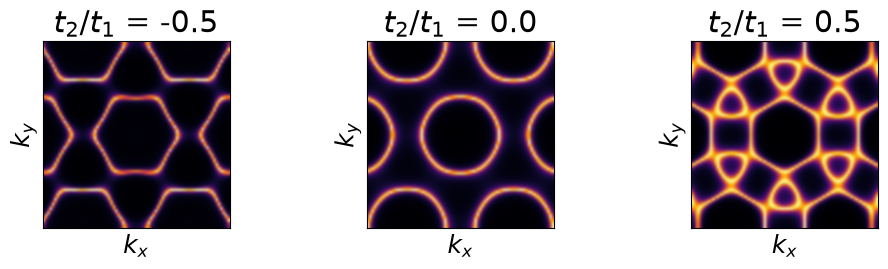

In [2]:
from pyqula import geometry
fig = plt.figure(figsize=(10,3))
g = geometry.triangular_lattice() # generate a triangular lattice
nk = 80 ; delta = 30./nk # smearing and kmesh
t2s = np.linspace(-0.5,0.5,3) # loop over t2s
ip = 1 # counter for the plot
for t2 in t2s: # loop over t2s
    h = g.get_hamiltonian(tij=[1.,t2]) ; h.set_filling(0.5,nk=10) # generate the Hamiltonian at half filling
    (x,y,d) = h.get_fermi_surface(e=0.,delta=delta,nk=nk) # compute Fermi surface
    plt.subplot(1,len(t2s),ip) ; ip += 1 # set subplot
    d2d = d.reshape((nk,nk)) ; plt.imshow(d2d,vmin=0.,vmax=2./delta,cmap="inferno",interpolation="bicubic") 
    plt.title("$t_2/t_1$ = "+str(np.round(t2,2))) ; plt.xticks([]) ; plt.yticks([])
    plt.xlabel("$k_x$") ; plt.ylabel("$k_y$")
plt.tight_layout()

### Quiz
- Replace the triangular lattice by a square lattice (square_lattice), recompute the spinon Fermi surfaces
- Replace the triangular lattice by a Kagome lattice (kagome_lattice), recompute the spinon Fermi surfaces
- Discuss why the effective tight binding model should be enforced to be at half filling
- Discuss how the hoppings of the quantum spin liquid depend on the exchange coupling of the parent Heisenberg model

#### In the lab
- Signatures of spinon Fermi surfaces in the triangular lattice have been observed with scanning tunnel microscopy
https://www.nature.com/articles/s41567-021-01321-0

## Quantum magnetism in the Kondo lattice (***Core***)
We now explore how the electronic structure of a van der Waals material is modified in the presence of a Kondo lattice. In the screened regime, a Kondo lattice will open up a heavy fermion gap in a metallic 2D material

The Kondo lattice couples conduction electrons to localized moments via $H_K=J_K\sum_i \mathbf S_i\cdot\boldsymbol\sigma_i$. In the screened regime this is captured by an auxiliary-fermion mean-field theory: the localized spins become a flat, dispersionless band of "heavy" fermions that hybridizes with the dispersive conduction band. The flat blue band is this localized-moment band, and the anticrossing with the conduction band is the hybridization gap responsible for heavy-fermion and Kondo-insulator behavior.

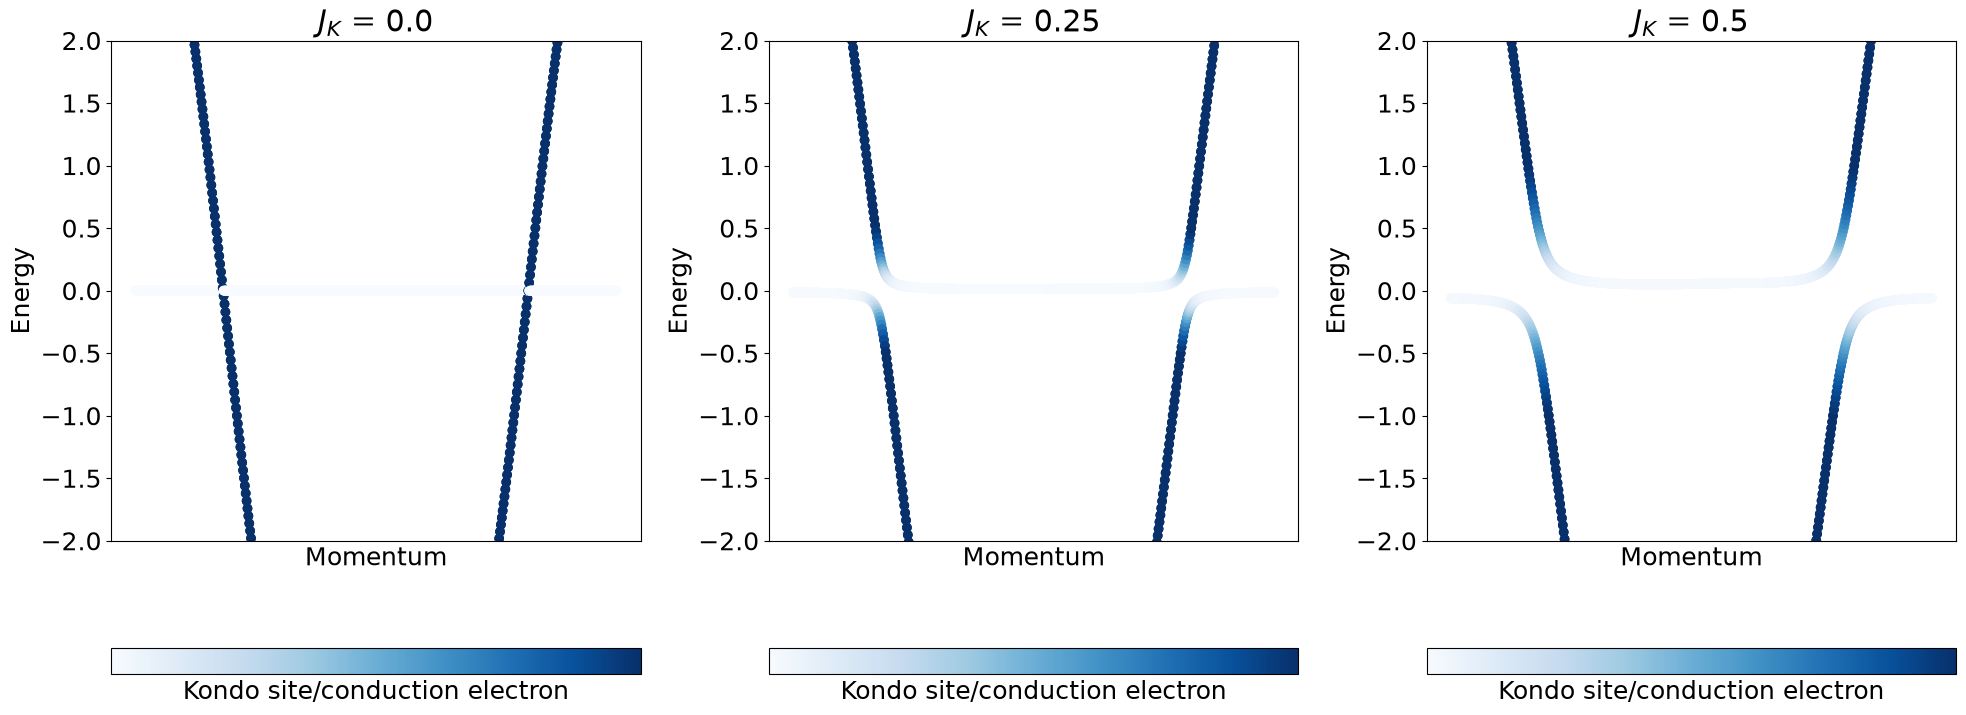

In [3]:
from pyqula import geometry
from pyqula.specialhamiltonian import H2HFH # promote a Hamiltonian to a heavy-fermion Hamiltonian
JKs = np.linspace(0.,.5,3) # chemical potentials
g = geometry.triangular_lattice() # take a triangular lattice
iw = 1 # counter
for JK in JKs: # loop over local potentials
    h = g.get_hamiltonian() ; h.add_onsite(-2.0) # generate Hamiltonian
    h = H2HFH(h,JK=JK) # add a Kondo lattice in the fully screened regime 
    plt.subplot(1,len(JKs),iw) 
    iw +=1 ; plt.title("$J_K$ = "+str(np.round(JK,3)))
    (k,e,c) = h.get_bands(operator="dispersive_electrons",kpath=["G","K","M","G"]) # compute band structure
    plt.scatter(k,e,c=c,cmap="Blues",vmin=0.,vmax=0.8) ; plt.xlabel("Momentum") ; plt.ylabel("Energy") 
    plt.xticks([]) ; plt.ylim([-2.,2.])
    plt.colorbar(label="Kondo site/conduction electron",ticks=[],orientation="horizontal")
plt.tight_layout() # adjust

### Quiz
- Discuss what is the origin of the flat blue band
- Discuss what is the physical origin of the anticrossing between the blue and red band
- Change the chemical potential. Do you still observe a gap opening in the electronic structure? Discuss why

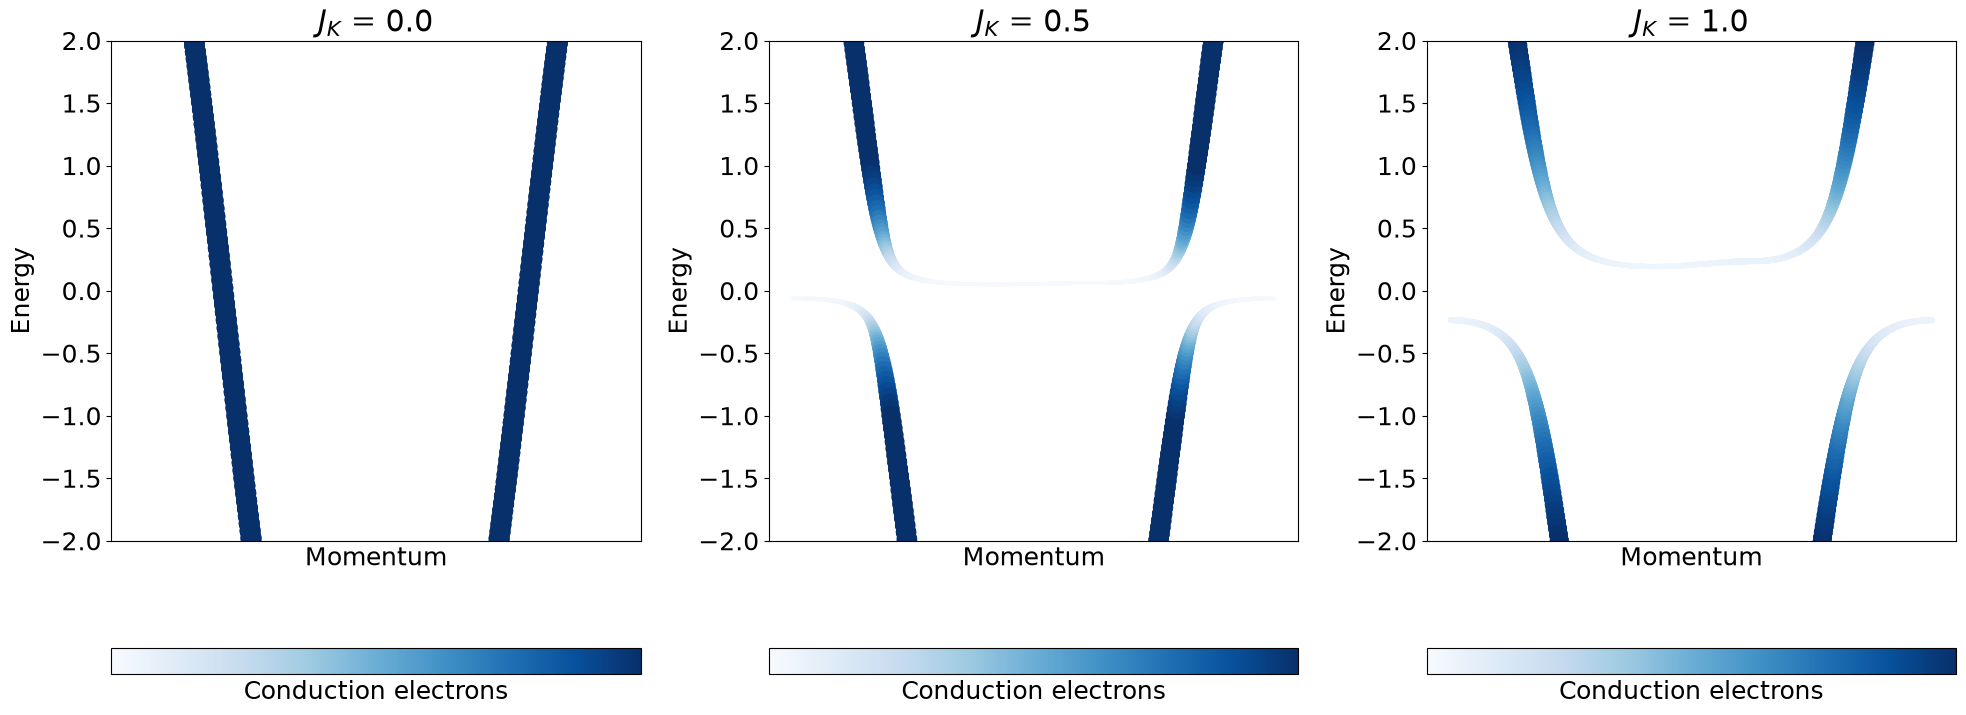

In [4]:
from pyqula import geometry
from pyqula.specialhamiltonian import H2HFH # promote a Hamiltonian to a heavy-fermion Hamiltonian
JKs = np.linspace(0.,1.,3) # chemical potentials
g = geometry.triangular_lattice() # take a triangular lattice
iw = 1 # counter
for JK in JKs: # loop over local potentials
    h = g.get_hamiltonian() ; h.add_onsite(-2.0) # generate Hamiltonian
    h = H2HFH(h,JK=JK) # add a Kondo lattice in the fully screened regime 
    plt.subplot(1,len(JKs),iw) 
    iw +=1 ; plt.title("$J_K$ = "+str(np.round(JK,3)))
    (k,e,c) = h.get_bands(operator="dispersive_electrons",kpath=["G","K","M","G"]) # compute band structure
    plt.scatter(k,e,c=c,s=200*c,cmap="Blues",vmin=0.,vmax=0.8) ; plt.xlabel("Momentum") ; plt.ylabel("Energy") 
    plt.xticks([]) ; plt.ylim([-2.,2.])
    plt.colorbar(label="Conduction electrons",ticks=[],orientation="horizontal")
plt.tight_layout() # adjust

### Quiz
- Change the chemical potential. Do you still observe a gap opening in the electronic structure? Discuss why
- Replace the triangular lattice by a honeycomb lattice. Do you observe a gap opening? Discuss why

#### In the lab
- Heavy fermions in a van der Waals heterostructure leading to a Kondo insulator have been observed in 1T-TaS2/1H-TaS2 heterostructures
https://www.nature.com/articles/s41586-021-04021-0

## Spinon dispersion in the Kondo lattice (***Challenge***)
We will now see what is the effect of a spinon dispersion in the Kondo lattice, emerging from an exchange coupling between the Kondo sites

Adding a direct exchange $J$ between the localized moments gives the previously flat heavy band a finite dispersion, since the local moments (spinons) can now hop between Kondo sites rather than only hybridizing locally with the conduction electrons. This is the lattice version of the Doniach picture: the Kondo coupling $J_K$ favors a local screened singlet, while $J$ favors magnetic correlations between the local moments, and their competition controls which regime is stable.

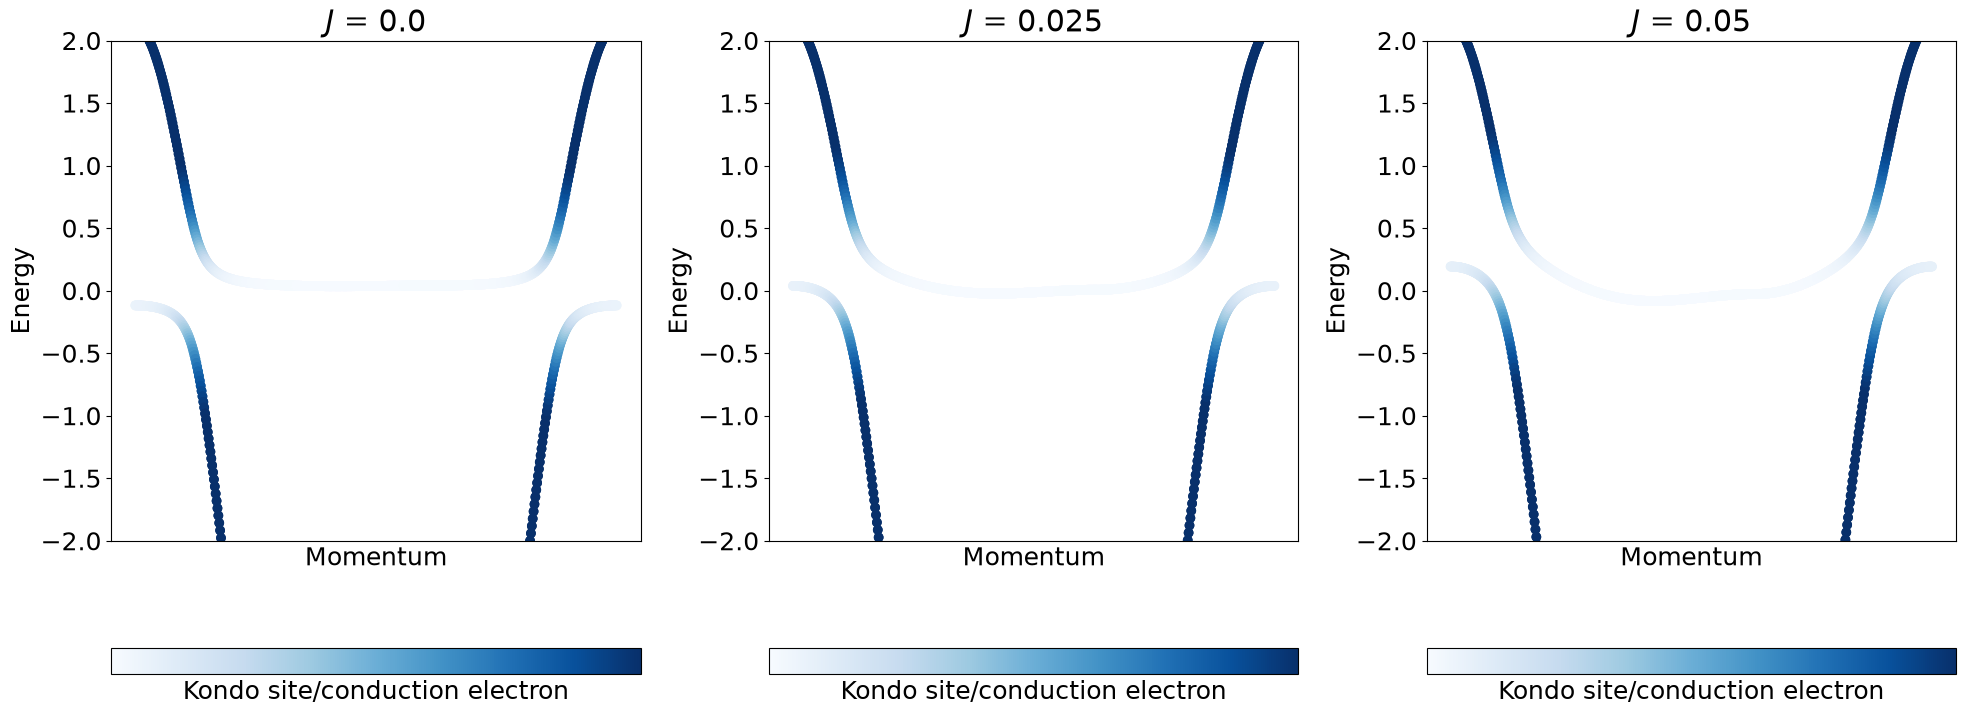

In [5]:
from pyqula import geometry
from pyqula.specialhamiltonian import H2HFH # promote a Hamiltonian to a heavy-fermion Hamiltonian
Js = np.linspace(0.,.05,3) # chemical potentials
g = geometry.triangular_lattice() # take a triangular lattice
iw = 1 # counter
for J in Js: # loop over local potentials
    h = g.get_hamiltonian() ; h.add_onsite(-4.0) # generate Hamiltonian
    h = H2HFH(h,JK=0.5,J=J) # add a Kondo lattice in the fully screened regime 
    plt.subplot(1,len(Js),iw) 
    iw +=1 ; plt.title("$J$ = "+str(np.round(J,3)))
    (k,e,c) = h.get_bands(operator="dispersive_electrons",kpath=["G","K","M","G"]) # compute band structure
    plt.scatter(k,e,c=c,cmap="Blues",vmin=0.,vmax=0.8) ; plt.xlabel("Momentum") ; plt.ylabel("Energy") 
    plt.xticks([]) ; plt.ylim([-2.,2.])
    plt.colorbar(label="Kondo site/conduction electron",ticks=[],orientation="horizontal")
plt.tight_layout() # adjust

### Quiz
- Why does the exchange coupling between Kondo impurities give rise to a dispersion in the spinons
- Which of the regimes has a more stable Kondo screened regime? Discuss why
- Increase the value of the Kondo coupling. What happens and why?
- Replace the triangular lattice by a honeycomb lattice. Do you observe a similar phenomenology? Discuss why

## Magnetization of a large Heisenberg model (***Core***)
Here we will show that a moderately large quantum Heisenberg model has zero magnetization

The antiferromagnetic Heisenberg ground state on a finite chain with an even number of spins is a global singlet, $S^z_{tot}=0$. A uniform field couples only to $S^z_{tot}=\sum_i S^z_i$, so as long as it is weaker than the finite-size gap to the neighboring $S^z_{tot}=\pm1$ sector, the ground state is completely unaffected and $\langle S^z_i\rangle=0$ on every site — a small field alone is not enough to induce any magnetization.

(0.0, 39.0)

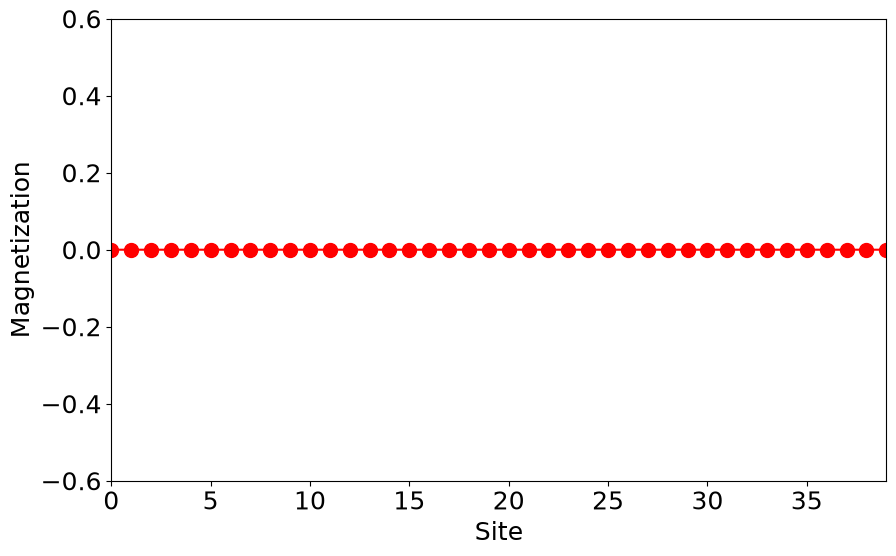

In [6]:
from dmrgpy import spinchain
n = 40 # number of sites
spins = ["S=1/2" for i in range(n)] # S=1/2 in each site
sc = spinchain.Spin_Chain(spins) # create spin chain object
h = 0 # initialize Hamiltonian
J = 1.0 # antiferromagnetic coupling, J=-1 for ferromagnetic coupling
Bz = -0.01 # small external magnetic field

for i in range(len(spins)-1): # Heisenberg coupling
    h = h + J*sc.Sx[i]*sc.Sx[i+1] ; h = h + J*sc.Sy[i]*sc.Sy[i+1] ; h = h + J*sc.Sz[i]*sc.Sz[i+1]
    
for i in range(len(spins)): h = h + Bz*sc.Sz[i] # and lets add a small magnetic field

plt.figure(figsize=(10,6))
sc.set_hamiltonian(h) # set the Hamiltonian
iis = range(n)
cs = [sc.vev(sc.Sz[i]) for i in iis] # compute the vacuum expectation value

plt.plot(iis,cs,marker="o",c="red",markersize=10)
plt.xlabel("Site") ; plt.ylabel("Magnetization") ; plt.ylim([-0.6,0.6]) ; plt.xlim([min(iis),max(iis)])

### Quiz
- Why is the magnetization zero everywhere even though there is a small external magnetic field?
- Make the value of the exchange negative, what happens and why?
- Take the case with antiferromagnetic coupling, and increase the value of the magnetic field. When do you get a finite magnetization and why?

## Magnetization of a large Heisenberg model with a magnetic impurity (***Challenge***)

Pinning a strong local field $B_z$ only at site $0$ forces a finite moment there; the rest of the chain responds through the antiferromagnetic spin correlations of the critical Heisenberg chain, which decay algebraically (with a staggered $(-1)^i$ sign) rather than exponentially — so the induced magnetization spreads over many sites before dying out, tracing out the correlation profile of a gapless spin liquid.

(0.0, 39.0)

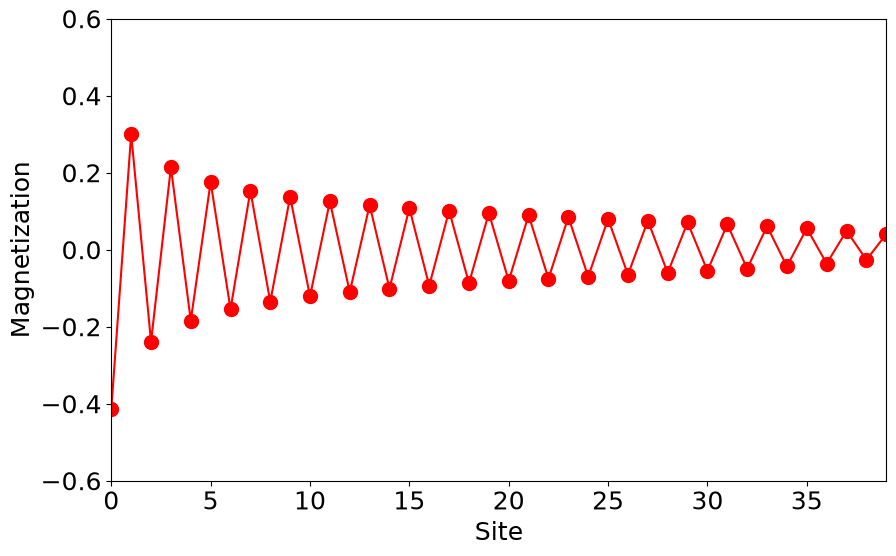

In [7]:
from dmrgpy import spinchain
n = 40 # length of the system
spins = ["S=1/2" for i in range(n)] # S=1/2 in each site
sc = spinchain.Spin_Chain(spins) # create spin chain object
h = 0 # initialize Hamiltonian
for i in range(len(spins)-1):
    h = h + sc.Sx[i]*sc.Sx[i+1]
    h = h + sc.Sy[i]*sc.Sy[i+1]
    h = h + sc.Sz[i]*sc.Sz[i+1]

    
Bz = 1. # local field
h = h + Bz*sc.Sz[0]
    
sc.set_hamiltonian(h) # create the Hamiltonian
iis = range(n)
cs = [sc.vev(sc.Sz[i],mode="DMRG") for i in iis]

plt.figure(figsize=(10,6))
plt.plot(iis,cs,marker="o",c="red",markersize=10)
plt.xlabel("Site") ; plt.ylabel("Magnetization") ; plt.ylim([-0.6,0.6]) ; plt.xlim([min(iis),max(iis)])

### Quiz
- Why does the magnetization decay away from the magnetic site?
- Remove the XX and YY couplings. What happens and why?

## Magnetization of a dimerized Heisenberg model with a magnetic impurity (***Challenge***)
Here we will now add a magnetic impurity to a dimerized quantum Heisenberg model, and see how the magnetization decays with distance

Alternating the exchange $J=1\pm0.2(-1)^i$ dimerizes the chain into a valence-bond-solid state with a finite spin gap. Because the ground state is now gapped, spin correlations decay exponentially with a finite correlation length rather than the algebraic decay of the uniform (gapless) chain above, which is why the impurity-induced magnetization here dies out over just a few sites instead of spreading through the whole system.

(0.0, 39.0)

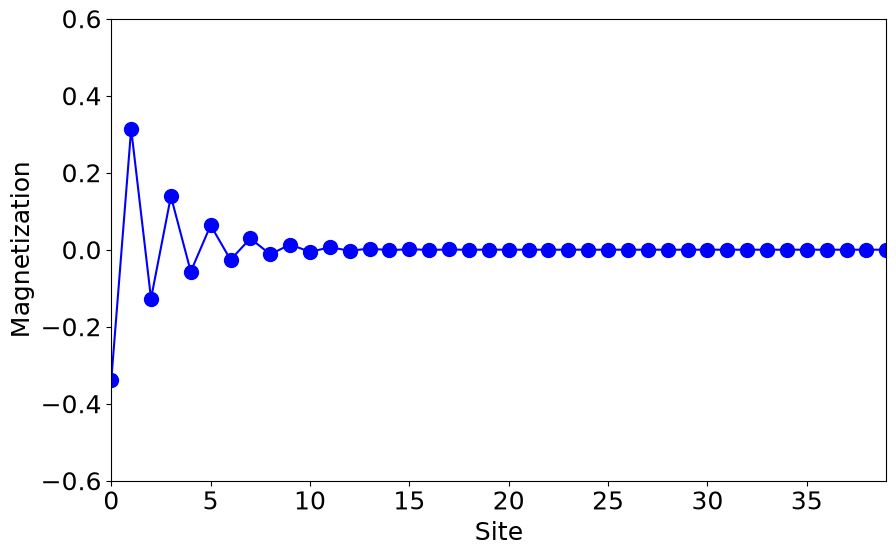

In [8]:
from dmrgpy import spinchain
n = 40 # length of the system
spins = ["S=1/2" for i in range(n)] # S=1/2 in each site
sc = spinchain.Spin_Chain(spins) # create spin chain object
h = 0 # initialize Hamiltonian
for i in range(len(spins)-1):
    J = 1.0 + .2*(-1)**i
    h = h + J*sc.Sx[i]*sc.Sx[i+1]
    h = h + J*sc.Sy[i]*sc.Sy[i+1]
    h = h + J*sc.Sz[i]*sc.Sz[i+1]

    
Bz = 1. # local field
h = h + Bz*sc.Sz[0]
    
sc.set_hamiltonian(h) # create the Hamiltonian
iis = range(n)
cs = [sc.vev(sc.Sz[i],mode="DMRG") for i in iis]

plt.figure(figsize=(10,6))
plt.plot(iis,cs,marker="o",c="blue",markersize=10)
plt.xlabel("Site") ; plt.ylabel("Magnetization") ; plt.ylim([-0.6,0.6]) ; plt.xlim([min(iis),max(iis)])

### Quiz
- Why is the local magnetization decreasing?
- Why is the decrease much faster than the case above?
- Remove the XX and YY couplings. What happens and why?